**APLICACION DE UN MODELO DE MACHINE LEARNING DE REGRESION LINEAL**

Lo primero es importar cada una de las librería vamos a estar utilizando para el pre-procesamiento, la creación del modelo y la evaluación, además de conectarlo a nuestro Google Drive para acceder a los datos

In [ ]:
# 1. Importamos las librerías a utilizar
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from google.colab import drive

# 2. Montamos en nuestro Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Después de importar, cargamos el archivo de datos y realizamos una limpieza básica. Esto también incluye el corregir las inconsistencias de escritura en una de las columnas, la cuál es **Item_Fat_Content** para que solo existan dos categorías principales: **Low Fat y Regular**.

In [ ]:
# 3. Cargamos los datos y posteriormente, los limpiamos
ruta_archivo = '/content/drive/MyDrive/Inteligencia Artificial/Unidad 2/bigMartSales.csv'
sales_df = pd.read_csv(ruta_archivo)

# Estandarizamos la columna 'Item_Fat_Content'
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].replace(
    {'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'}
)

Ahora comenzamos a separar nuestra variable objetivo de las características predictoras (eliminando los identificadores que no aportan algún valor al modelo). Luego podemos construir un **pipeline** que descartará los valores nulos, escalará los números y aplicará **One-Hot Encoding** a las categorías, para finalmente entrenar y evaluar la regresión lineal.

In [ ]:
# 4. Separamos las características (X) y objetivo (y)
X = sales_df.drop(columns=['Item_Outlet_Sales', 'Item_Identifier', 'Outlet_Identifier'])
y = sales_df['Item_Outlet_Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 5. Configuramos el pre-procesamiento
cat_selector = make_column_selector(dtype_include='object')
num_selector = make_column_selector(dtype_include='number')

num_pipeline = make_pipeline(SimpleImputer(strategy='mean'), StandardScaler())
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore', sparse_output=False))

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_selector),
        ('cat', cat_pipeline, cat_selector)
    ]
)

# 6. Creamos, entrenamos y evaluamos el modelo
lin_reg_pipeline = make_pipeline(preprocessor, LinearRegression())
lin_reg_pipeline.fit(X_train, y_train)

y_pred_lin = lin_reg_pipeline.predict(X_test)
print("--- Resultados Regresión Lineal ---")
print(f"R^2 (Aceptación): {r2_score(y_test, y_pred_lin):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_lin):.2f}")

--- Resultados Regresión Lineal ---
R^2 (Aceptación): 0.5677
MSE: 1210761.55


# Análisis Gráfico de los Resultados
Una vez que hemos ya evaluado nuestro modelo con las métricas de R² y MSE, lo que sigue es visualizar que tan bie está prediciendo nuestro modelo. Para esto crearemos un gráfico de dispersión (scatter plot) comparando las ventas reales (y_test) contra las predicciones de nuestro modelo (y_pred_lin).

Si el modelo fuera "perfecto", cada uno de los puntos formarían una línea recta diagonal.

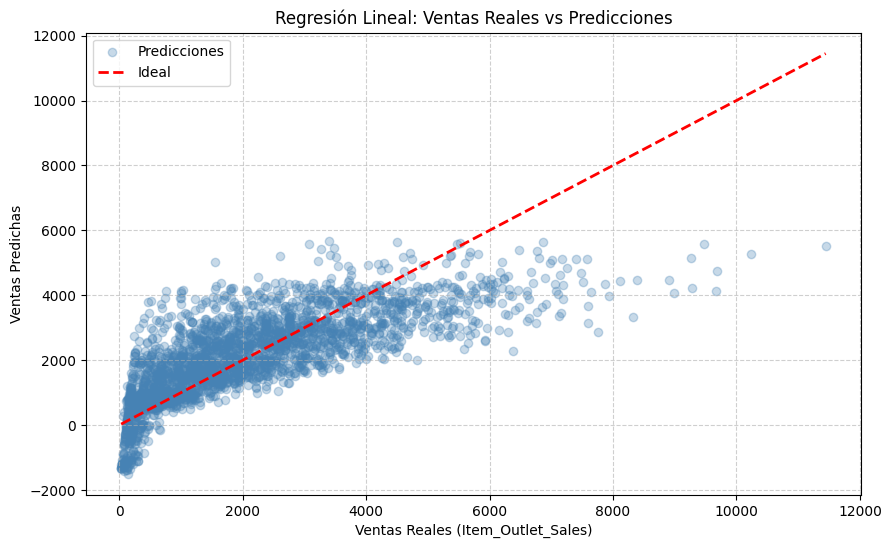

In [ ]:
# 7. Visualizamos las Ventas Reales vs Predicciones
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

# Creamos un gráfico de dispersión de los datos reales vs predichos
plt.scatter(y_test, y_pred_lin, alpha=0.3, color='steelblue', label='Predicciones')

# Línea de referencia (predicción perfecta)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2, label='Ideal')

plt.title('Regresión Lineal: Ventas Reales vs Predicciones')
plt.xlabel('Ventas Reales (Item_Outlet_Sales)')
plt.ylabel('Ventas Predichas')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Extracción e Interpretación de Coeficientes
La mayor ventaja de la Regresión Lineal es su interpretabildiad, pudiendo extraer los "coeficientes" matemáticos que el modelo asignó a cada variable. Un coeficiente positivo alto significa que esa característica impulsa las ventas hacia arriba, mientras que un coeficiente negativo indica que disminuye las ventas.

En el siguiente bloque extraemos estos valores directamente de nuestro **pipeline** para ver que factores son los más determinantes para las ventas en las tiendas.

In [ ]:
# 8. Analizamos los coeficientes del modelo
# Extraemos los componentes del pipeline
modelo_regresion = lin_reg_pipeline.named_steps['linearregression']
preprocesador = lin_reg_pipeline.named_steps['columntransformer']

# Obtenemos los nombres de las columnas categóricas transformadas (OneHotEncoding)
nombres_cat = preprocesador.named_transformers_['cat'].named_steps['onehotencoder'].get_feature_names_out(cat_selector(X))

# Obtenemos también los nombres de las columnas numéricas
nombres_num = num_selector(X)

# Unimos todos los nombres en el mismo orden que entraron al modelo
nombres_todas_caracteristicas = list(nombres_num) + list(nombres_cat)

# Creamos un DataFrame para visualizar mejor los coeficientes
df_coeficientes = pd.DataFrame({
    'Característica': nombres_todas_caracteristicas,
    'Impacto (Coeficiente)': modelo_regresion.coef_
})

# Ordenamos de mayor a menor impacto
df_coeficientes = df_coeficientes.sort_values(by='Impacto (Coeficiente)', ascending=False)

print("--- Factores que más AUMENTAN las ventas ---")
display(df_coeficientes.head(5))

print("\n--- Factores que más DISMINUYEN las ventas ---")
display(df_coeficientes.tail(5))

--- Factores que más AUMENTAN las ventas ---


,Característica,Impacto (Coeficiente)
31,Outlet_Type_Supermarket Type3,2199.876731
2,Item_MRP,990.265433
22,Outlet_Size_High,598.080898
18,Item_Type_Seafood,334.116504
3,Outlet_Establishment_Year,316.484726



--- Factores que más DISMINUYEN las ventas ---


,Característica,Impacto (Coeficiente)
27,Outlet_Location_Type_Tier 3,-225.751017
24,Outlet_Size_Small,-273.113070
23,Outlet_Size_Medium,-324.967829
30,Outlet_Type_Supermarket Type2,-403.074272
28,Outlet_Type_Grocery Store,-1643.532626
